In [1]:
# --- Cell: imports ---
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import sys
sys.path.append('.')  # folder containing vti_magnetic_import.py
from vti_magnetic_import import load_vti_sample, inspect_vti

from scipy.ndimage import gaussian_filter, map_coordinates
from skimage.measure import marching_cubes
import pyvista as pv

import matplotlib.ticker as mticker
import pandas as pd

import json

import Functions_3D as EB


In [2]:
def load_sample_data(save_dir, sample_name, date):
    """
    Load back the volume, wall_df, and metadata for one sample, as saved
    by save_sample_data.
    """
    volume_path = os.path.join(save_dir, f'{sample_name}_volume_{date}.npz')
    df_path = os.path.join(save_dir, f'{sample_name}_wall_df_{date}.csv')
    meta_path = os.path.join(save_dir, f'{sample_name}_volume_analysis_metadata_{date}.json')

    npz = np.load(volume_path)
    cropped = {
        'Mx': npz['Mx'], 'My': npz['My'], 'Mz': npz['Mz'],
        'magnitude': npz['magnitude'],
        'shape': tuple(npz['shape']),
    }
    spacing = tuple(npz['spacing'])
    z_offset = 0 #int(npz['z_offset'])

    wall_df = pd.read_csv(df_path)

    with open(meta_path) as f:
        metadata = json.load(f)

    return cropped, wall_df, spacing,z_offset, metadata

In [3]:
sample_names = ['270', '105', '665', '452'] 
dates = ['14AUG26_interpolated', '22AUG26_interpolated', '22AUG26_interpolated', '14AUG26_interpolated']
sample_colors = ['deeppink', 'cyan', 'gold', 'limegreen']
all_wall_dfs = []
volumes = {}
data_dir = r"C:\Users\emmab\Projects\Vector_Tomography\data_dir"

for name, date in zip(sample_names, dates):
    print(name)
    cropped, wall_df, spacing, z_offset, meta = load_sample_data(data_dir, name, date)
    volumes[name] = cropped
    wall_df = wall_df.copy()
    wall_df['sample'] = name          # tag rows so we can group by sample later
    all_wall_dfs.append(wall_df)

combined_df = pd.concat(all_wall_dfs, ignore_index=True)
# Now you can group by sample_name for direct comparison, e.g.:
#combined_df.groupby('sample_name')['psi_chiral'].agg(['mean', 'std', 'count'])


figure_name = {
    'psi_unsigned': 'ψ',
    'psi_unsigned': 'ψ', 
    'M_normal': '||Surface Normal||', 
    'Exchange': '(∇·M)$^2$',
    'curl_magnitude': '||∇×M||',
    'PMA': 'PMA',
    'iDMI': 'iDMI',
}

sample_names_plot = ['[Co(0.2 nm)/ Ni(0.7 nm)]', '[Co(1.0 nm)/ Pt(0.5 nm)]', '[Co(0.6 nm)/ Ni(0.6 nm)/ Pt(0.5 nm)]', '[Co(0.4 nm)/ Ni(0.5 nm)/ Pt(0.2 nm)]'] 

270
105
665
452


In [4]:
def plot_angle_vs_z(combined_df, sample_names, sample_names_plot, sample_colors, figure_name, bounds,
                     angle_col='psi_chiral', bloch_axis=None, neel_axis=None,
                     title=None):
    """
    Plot angle_col vs. z-layer for every sample in sample_names, each drawn
    in its corresponding sample_colors entry, on one shared set of axes.

    Returns a dict of {sample_name: grouped_df} so per-sample stats are
    still accessible after plotting.
    """
    z_lo, z_hi = bounds
    z_min = z_lo - z_lo
    z_max = z_hi - z_lo

    fig, ax = plt.subplots(figsize=(6, 4))
    grouped_results = {}

    for name, color, comp in zip(sample_names, sample_colors, sample_names_plot):
        df = combined_df[combined_df['sample'] == name].copy()

        df['z_layer'] = df['iz'].round().astype(int)

        n_before = len(df)
        df = df[(df['z_layer'] >= z_min) & (df['z_layer'] <= z_max)]
        print(f"{name}: {len(df)} / {n_before} vertices fall within layers {z_min}-{z_max}")

        grouped = df.groupby('z_layer')[angle_col].agg(['mean', 'std', 'count'])
        grouped_results[name] = grouped

        ax.errorbar(grouped.index, grouped['mean'], yerr=grouped['std'],
                     fmt='o-', capsize=3, color=color, label=comp)

    if bloch_axis is None:
        print('no axis')
    else:
        print(bloch_axis)
        for deg in bloch_axis:
            ax.axhline(deg, color='magenta')

    if neel_axis == None:  
        print('no neel axis')
    else:
        for deg in neel_axis:
            ax.axhline(deg, color='cyan')

    ax.set_xlabel('z voxel layer', font = 'times')
    ax.set_xticks(range(z_min, z_max))
    ax.set_ylabel(f'{figure_name[angle_col]}')
    # ax.set_title(f'{angle_col} vs. thickness position \n {title}')
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    ax.legend()
    plt.tight_layout()
    plt.show()

    return grouped_results

270: 210875 / 210875 vertices fall within layers 0-10
105: 75721 / 75721 vertices fall within layers 0-10
665: 26731 / 26731 vertices fall within layers 0-10
452: 74386 / 74386 vertices fall within layers 0-10
[45]


findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.


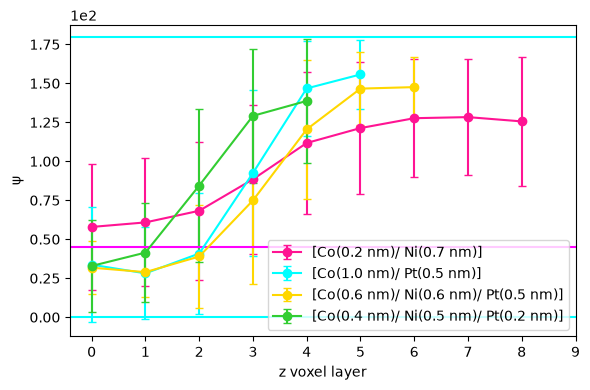

findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.


270: 210875 / 210875 vertices fall within layers 0-10
105: 75721 / 75721 vertices fall within layers 0-10
665: 26731 / 26731 vertices fall within layers 0-10
452: 74386 / 74386 vertices fall within layers 0-10
[0]
no neel axis


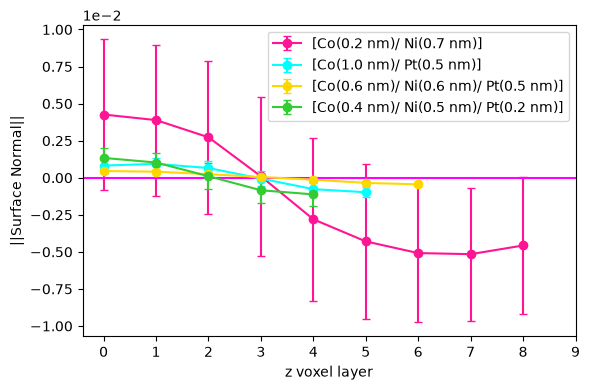

{'270':              mean       std  count
 z_layer                           
 0        0.004264  0.005101  18837
 1        0.003889  0.005086  21364
 2        0.002731  0.005173  32810
 3        0.000097  0.005382  20885
 4       -0.002802  0.005508  32191
 5       -0.004293  0.005230  20370
 6       -0.005080  0.004671  31492
 7       -0.005154  0.004483  20768
 8       -0.004569  0.004643  12158,
 '105':              mean       std  count
 z_layer                           
 0        0.000821  0.000484   9929
 1        0.000939  0.000426  10437
 2        0.000656  0.000479  17289
 3       -0.000054  0.000487  10714
 4       -0.000770  0.000408  17119
 5       -0.000976  0.000329  10233,
 '665':              mean       std  count
 z_layer                           
 0        0.000452  0.000134   2961
 1        0.000411  0.000120   3237
 2        0.000238  0.000165   4996
 3        0.000052  0.000162   3262
 4       -0.000134  0.000163   5086
 5       -0.000347  0.000148   3141
 6   

In [5]:
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors,figure_name,   bounds=(0, 10),angle_col='psi_unsigned',  bloch_axis = [45] , neel_axis = [0, 180], title = '' )
#plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors,figure_name,  bounds=(0, 10), angle_col='psi_chiral', bloch_axis = [-45, 45] , neel_axis = [-180, 0, 180], title = '')

mz_max = combined_df.loc[combined_df['sample'] == '270', 'Mz']
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors, figure_name, bounds=(0, 10), angle_col='M_normal', bloch_axis = [0] , neel_axis = None, title = '' )

findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.


270: 210875 / 210875 vertices fall within layers 0-10
105: 75721 / 75721 vertices fall within layers 0-10
665: 26731 / 26731 vertices fall within layers 0-10
452: 74386 / 74386 vertices fall within layers 0-10
no axis
no neel axis


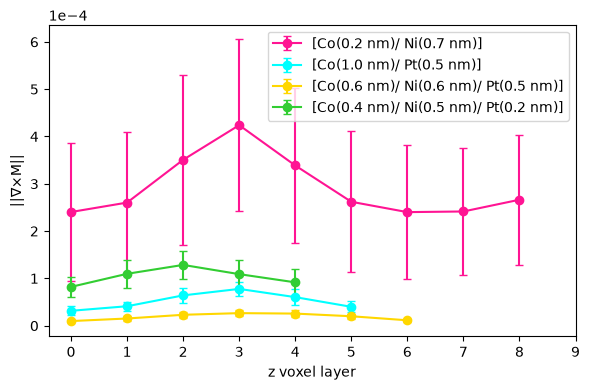

findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.


270: 210875 / 210875 vertices fall within layers 0-10
105: 75721 / 75721 vertices fall within layers 0-10
665: 26731 / 26731 vertices fall within layers 0-10
452: 74386 / 74386 vertices fall within layers 0-10
no axis
no neel axis


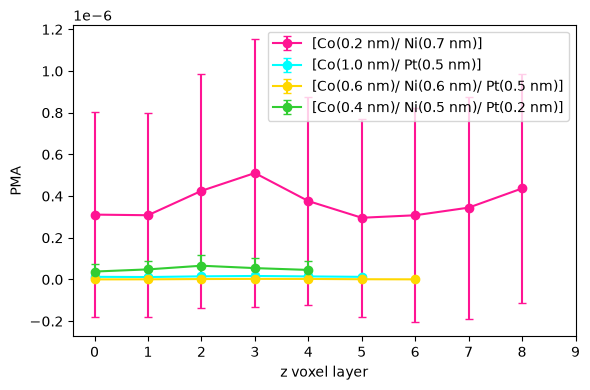

270: 210875 / 210875 vertices fall within layers 0-10
105: 75721 / 75721 vertices fall within layers 0-10
665: 26731 / 26731 vertices fall within layers 0-10
452: 74386 / 74386 vertices fall within layers 0-10
no axis
no neel axis


KeyError: 'Divergence'

findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.
findfont: Font family 'times' not found.


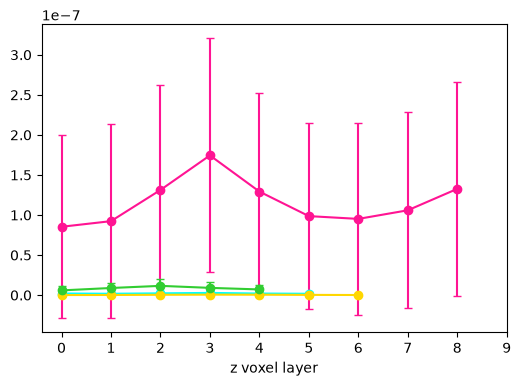

In [6]:
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors, figure_name, bounds=(0, 10), angle_col='curl_magnitude')
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors,figure_name, bounds=(0, 10), angle_col='PMA')
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors,figure_name, bounds=(0, 10), angle_col='Divergence')
plot_angle_vs_z(combined_df,sample_names, sample_names_plot, sample_colors, figure_name,bounds=(0, 10), angle_col='iDMI')

# identify the location of Bloch lines in the wall as a function of z

In [ ]:
def compute_M_normal_zero_by_z_from_df(combined_df, tol=1e-3, sample_col='sample'):
    """
    For a combined per-vertex wall DataFrame (multiple samples stacked,
    tagged by sample_col), identify vertices where M_normal is
    approximately zero, and compute the fraction of such vertices per
    z-layer, separately for each sample.

    Parameters
    ----------
    combined_df : pd.DataFrame
        Must contain 'M_normal', 'iz' (fractional voxel z-index), and
        sample_col (identifying which sample each row belongs to).
    tol : float
        Tolerance for |M_normal| < tol to count as a zero-crossing.
    sample_col : str
        Name of the column identifying sample membership (here, 'sample').

    Returns
    -------
    per_z_list : list of pd.DataFrame
        One DataFrame per sample, each with 'z_layer', 'fraction',
        'count', 'total', 'sample_name' -- directly usable with
        plot_M_normal_zero_across_samples.
    """
    if 'M_normal' not in combined_df.columns:
        raise KeyError("combined_df must contain an 'M_normal' column; "
                        "add it first, e.g. wall_df['M_normal'] = "
                        "wall_df['Mx']*wall_df['nx'] + wall_df['My']*wall_df['ny'] "
                        "+ wall_df['Mz']*wall_df['nz']")

    df = combined_df.copy()
    df['z_layer'] = df['iz'].round().astype(int)
    df['is_zero'] = df['M_normal'].abs() < tol

    per_z_list = []
    for name, group in df.groupby(sample_col):
        summary = (group.groupby('z_layer')['is_zero']
                         .agg(fraction='mean', fraction_std='std',
                              count='sum', total='size')
                         .reset_index())
        summary['fraction_std'] = summary['fraction_std'].fillna(0.0)  # single-vertex layers -> std undefined
        summary['fraction_sem'] = summary['fraction_std'] / np.sqrt(summary['total'])
        summary['sample_name'] = name
        per_z_list.append(summary)
        print(f"[{name}] {group['is_zero'].sum()} / {len(group)} vertices "
              f"with |M_normal| < {tol}")

    return per_z_list

In [ ]:
def plot_M_normal_zero_across_samples(per_z_list,sample_names, sample_colors, error_col='fraction_std'):
    """
    Compare the fraction of M_normal-zero voxels per z-layer across
    multiple samples, plotting individual sample curves plus the
    across-sample mean +/- std.

    Parameters
    ----------
    per_z_list : list of pd.DataFrame
        Each element is the 'per_z' output of compute_M_normal_zero_by_z
        for one sample (must include 'z_layer', 'fraction', 'sample_name').
        Samples may have different numbers of z-layers; z_layer is used
        as the common alignment axis (0-indexed relative position),
        which assumes samples have been consistently cropped to the
        same z-offset convention discussed earlier.

    Returns
    -------
    combined : pd.DataFrame
        All per_z tables concatenated, plus the across-sample summary
        (mean, std, count) grouped by z_layer.
    """
    combined = pd.concat(per_z_list, ignore_index=True)

    fig, ax = plt.subplots(figsize=(7, 5))
    # colors = plt.get_cmap(cmap)

    for i, (name, group) in enumerate(combined.groupby('sample_name')):
        if name == '270': 
            colors = sample_colors[1]
        elif name == '452': 
            colors = sample_colors[0]
        ax.errorbar(group['z_layer'], group['fraction'], yerr=group[error_col],
                    fmt='o-', color=colors, capsize=3, label=name)

    #summary = combined.groupby('z_layer')['fraction'].agg(['mean', 'std', 'count'])
    # ax.errorbar(summary.index, summary['mean'], yerr=summary['std'],
    #             fmt='ks-', capsize=4, linewidth=2, label='mean across samples')

    ax.set_xlabel('z voxel layer')
    ax.set_ylabel('fraction of voxels with M_normal ~ 0')
    ax.set_title('M_normal zero-crossing fraction vs. thickness layer')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    return combined, summary

[105] 47253 / 75721 vertices with |M_normal| < 0.001
[270] 16655 / 210875 vertices with |M_normal| < 0.001
[452] 32652 / 74386 vertices with |M_normal| < 0.001
[665] 26731 / 26731 vertices with |M_normal| < 0.001


UnboundLocalError: cannot access local variable 'colors' where it is not associated with a value

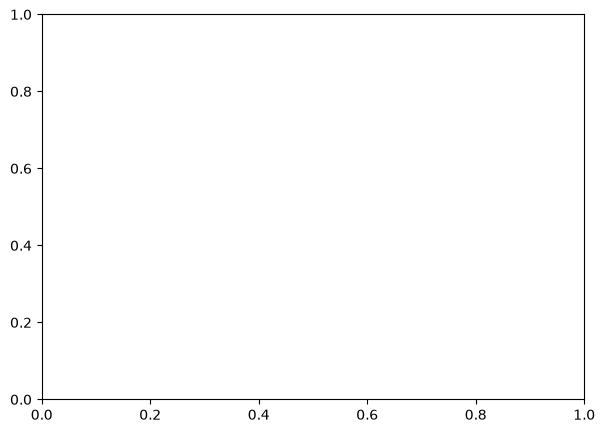

In [ ]:
per_z_list = compute_M_normal_zero_by_z_from_df(combined_df, tol=1e-3, sample_col='sample')
combined, summary = plot_M_normal_zero_across_samples(per_z_list, sample_names, sample_colors )